# Phase 2: Feature Engineering & Statistical Analysis
## Project: AI-Assisted Code "Silent Regression" Forecaster

### Research Context & Scope
- **Dataset Corpus:** ApacheJIT (MSR 2022 Data Showcase Track, [arXiv:2203.00101](https://arxiv.org/abs/2203.00101))
- **Target Ground Truth:** `buggy` (Defect-inducing changes identified via SZZ heuristic; not test-evading silent regressions).
- **Core Objective:** Conduct rigorous exploratory statistical analysis, hypothesis testing, multicollinearity diagnostics, feature engineering, and leakage-safe data preparation for downstream machine learning.
- **Strict Boundary:** No predictive model training is conducted in this phase.


In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Project module imports
from src.phase2_analysis import (
    ORIGINAL_NUMERIC_FEATURES,
    DERIVED_FEATURES,
    ALL_PREDICTOR_FEATURES,
    engineer_features,
    calculate_cliffs_delta,
    bootstrap_median_difference,
    benjamini_hochberg,
    perform_hypothesis_tests,
    compute_vif,
    compute_correlation_matrices
)

# Styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")


Pandas version: 3.0.1
NumPy version: 2.3.5


In [2]:
data_dir = Path('../data/raw')
if not data_dir.exists():
    data_dir = Path('data/raw')

print(f"Loading raw datasets from: {data_dir.resolve()}")
df_train = pd.read_csv(data_dir / 'apachejit_train.csv')
df_test = pd.read_csv(data_dir / 'apachejit_test_large.csv')

print(f"Training split shape: {df_train.shape} (Years {df_train['year'].min()}–{df_train['year'].max()})")
print(f"Test split shape:     {df_test.shape} (Years {df_test['year'].min()}–{df_test['year'].max()})")

# Overlap check
overlap = set(df_train['commit_id']).intersection(set(df_test['commit_id']))
print(f"Commit ID overlap count: {len(overlap)} (Strict chronological separation)")


Loading raw datasets from: C:\Users\sanja\Downloads\Data_Analytic_Project\data\raw


Training split shape: (44834, 18) (Years 2003–2016)
Test split shape:     (30111, 18) (Years 2017–2019)
Commit ID overlap count: 0 (Strict chronological separation)


In [3]:
target_df = pd.DataFrame([
    {
        'Split': 'Train (Balanced)',
        'Total Rows': len(df_train),
        'Clean Commits': int((~df_train['buggy']).sum()),
        'Defect Commits': int(df_train['buggy'].sum()),
        'Defect Rate %': round(float(df_train['buggy'].mean() * 100), 2),
        'Imbalance Ratio': round(float((~df_train['buggy']).sum() / df_train['buggy'].sum()), 2)
    },
    {
        'Split': 'Test Large (Realistic)',
        'Total Rows': len(df_test),
        'Clean Commits': int((~df_test['buggy']).sum()),
        'Defect Commits': int(df_test['buggy'].sum()),
        'Defect Rate %': round(float(df_test['buggy'].mean() * 100), 2),
        'Imbalance Ratio': round(float((~df_test['buggy']).sum() / df_test['buggy'].sum()), 2)
    }
])
display(target_df)


,Split,Total Rows,Clean Commits,Defect Commits,Defect Rate %,Imbalance Ratio
0,Train (Balanced),44834,22413,22421,50.01,1.00
1,Test Large (Realistic),30111,24293,5818,19.32,4.18


In [4]:
print("Executing feature engineering pipeline on train and test...")
X_train = engineer_features(df_train)
X_test = engineer_features(df_test)

print(f"Engineered Train Features: {X_train.shape}")
print(f"Engineered Test Features:  {X_test.shape}")
print(f"Feature columns match: {list(X_train.columns) == list(X_test.columns)}")
print(f"Total Predictors: {len(ALL_PREDICTOR_FEATURES)} (12 Original + 14 Derived)")

# Preview first 5 rows
display(X_train.head())


Executing feature engineering pipeline on train and test...


Engineered Train Features: (44834, 26)
Engineered Test Features:  (30111, 26)
Feature columns match: True
Total Predictors: 26 (12 Original + 14 Derived)


,la,ld,nf,nd,ns,ent,ndev,age,nuc,aexp,...,directories_per_file,experience_gap,log1p_la,log1p_ld,log1p_total_lines_changed,log1p_age,log1p_nuc,log1p_aexp,log1p_arexp,log1p_asexp
0,223.0,33.0,7.0,5.0,2.0,2.213687,0.142857,1.857143,12.142857,104.0,...,0.714286,0.0,5.411646,3.526361,5.549076,1.049822,2.575878,4.653960,4.653960,0.000606
1,138.0,10.0,9.0,3.0,1.0,1.692477,0.333333,32.333333,11.777778,287.0,...,0.333333,0.0,4.934474,2.397895,5.003946,3.506558,2.547708,5.662960,5.662960,5.433722
2,69.0,20.0,2.0,2.0,1.0,0.599911,1.500000,9.500000,16.500000,366.0,...,1.000000,0.0,4.248495,3.044522,4.499810,2.351375,2.862201,5.905362,5.905362,5.641907
3,52.0,2.0,2.0,2.0,1.0,0.380947,1.000000,6.000000,14.000000,364.0,...,1.000000,0.0,3.970292,1.098612,4.007333,1.945910,2.708050,5.899897,5.899897,5.634790
4,256.0,348.0,8.0,4.0,1.0,0.489213,0.375000,13.625000,20.000000,253.0,...,0.500000,0.0,5.549076,5.855072,6.405228,2.682732,3.044522,5.537334,5.537334,5.298317


In [5]:
print("Running formal hypothesis tests on training corpus...")
hypothesis_results = perform_hypothesis_tests(df_train, target_col='buggy', random_seed=42)

# Format summary table
h_summary = []
for t in hypothesis_results['numeric_hypotheses']:
    h_summary.append({
        'Hypothesis': t['hypothesis_id'],
        'Feature': t['feature'],
        'Test': t['test_type'],
        'U Statistic': f"{t['test_statistic']:.2e}",
        'Raw p-value': f"{t['raw_p_value']:.2e}",
        'Adj q-value (BH)': f"{t['adjusted_p_value']:.2e}",
        "Cliff's Delta": t['effect_size_value'],
        'Magnitude': t['effect_size_magnitude'],
        'Median Diff [95% CI]': f"{t['median_difference']} [{t['median_diff_ci_95'][0]}, {t['median_diff_ci_95'][1]}]",
        'Significant (a=0.05)': t['significant_at_alpha_0_05']
    })

display(pd.DataFrame(h_summary))


Running formal hypothesis tests on training corpus...


,Hypothesis,Feature,Test,U Statistic,Raw p-value,Adj q-value (BH),Cliff's Delta,Magnitude,Median Diff [95% CI],Significant (a=0.05)
0,H1,total_lines_changed,Mann-Whitney U Test (Two-Sided),3.78e+08,0.00e+00,0.00e+00,0.5043,Large,"140.0 [136.0, 145.0]",True
1,H2,nf,Mann-Whitney U Test (Two-Sided),3.63e+08,0.00e+00,0.00e+00,0.4452,Medium,"3.0 [3.0, 3.0]",True
2,H3,ent,Mann-Whitney U Test (Two-Sided),3.50e+08,0.00e+00,0.00e+00,0.3946,Medium,"0.81 [0.79, 0.85]",True
3,H4_ndev,ndev,Mann-Whitney U Test (Two-Sided),2.23e+08,1.21e-94,1.56e-94,-0.1125,Negligible,"-0.5 [-0.6, -0.5]",True
4,H4_age,age,Mann-Whitney U Test (Two-Sided),2.89e+08,3.67e-165,6.60e-165,0.1490,Small,"8.75 [8.0, 9.57]",True
5,H4_nuc,nuc,Mann-Whitney U Test (Two-Sided),2.81e+08,7.81e-108,1.17e-107,0.1203,Negligible,"8.0 [7.14, 9.0]",True
6,H4_aexp,aexp,Mann-Whitney U Test (Two-Sided),2.26e+08,3.24e-75,3.24e-75,-0.1001,Negligible,"-102.0 [-114.0, -88.98]",True
7,H4_arexp,arexp,Mann-Whitney U Test (Two-Sided),2.25e+08,6.19e-83,6.96e-83,-0.1052,Negligible,"-71.98 [-81.0, -63.0]",True
8,H4_asexp,asexp,Mann-Whitney U Test (Two-Sided),1.87e+08,0.00e+00,0.00e+00,-0.2548,Small,"-64.0 [-69.0, -61.0]",True


C:\Users\sanja\AppData\Local\Temp\ipykernel_17208\1387371076.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df_train['buggy'], y=np.log1p(df_train['la'] + df_train['ld']), ax=axes[0, 0], palette=['#2b5c8f', '#d95f02'])
C:\Users\sanja\AppData\Local\Temp\ipykernel_17208\1387371076.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df_train['buggy'], y=np.log1p(df_train['nf']), ax=axes[0, 1], palette=['#2b5c8f', '#d95f02'])


C:\Users\sanja\AppData\Local\Temp\ipykernel_17208\1387371076.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df_train['buggy'], y=df_train['ent'], ax=axes[1, 0], palette=['#2b5c8f', '#d95f02'])
C:\Users\sanja\AppData\Local\Temp\ipykernel_17208\1387371076.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df_train['buggy'], y=np.log1p(df_train['asexp']), ax=axes[1, 1], palette=['#2b5c8f', '#d95f02'])


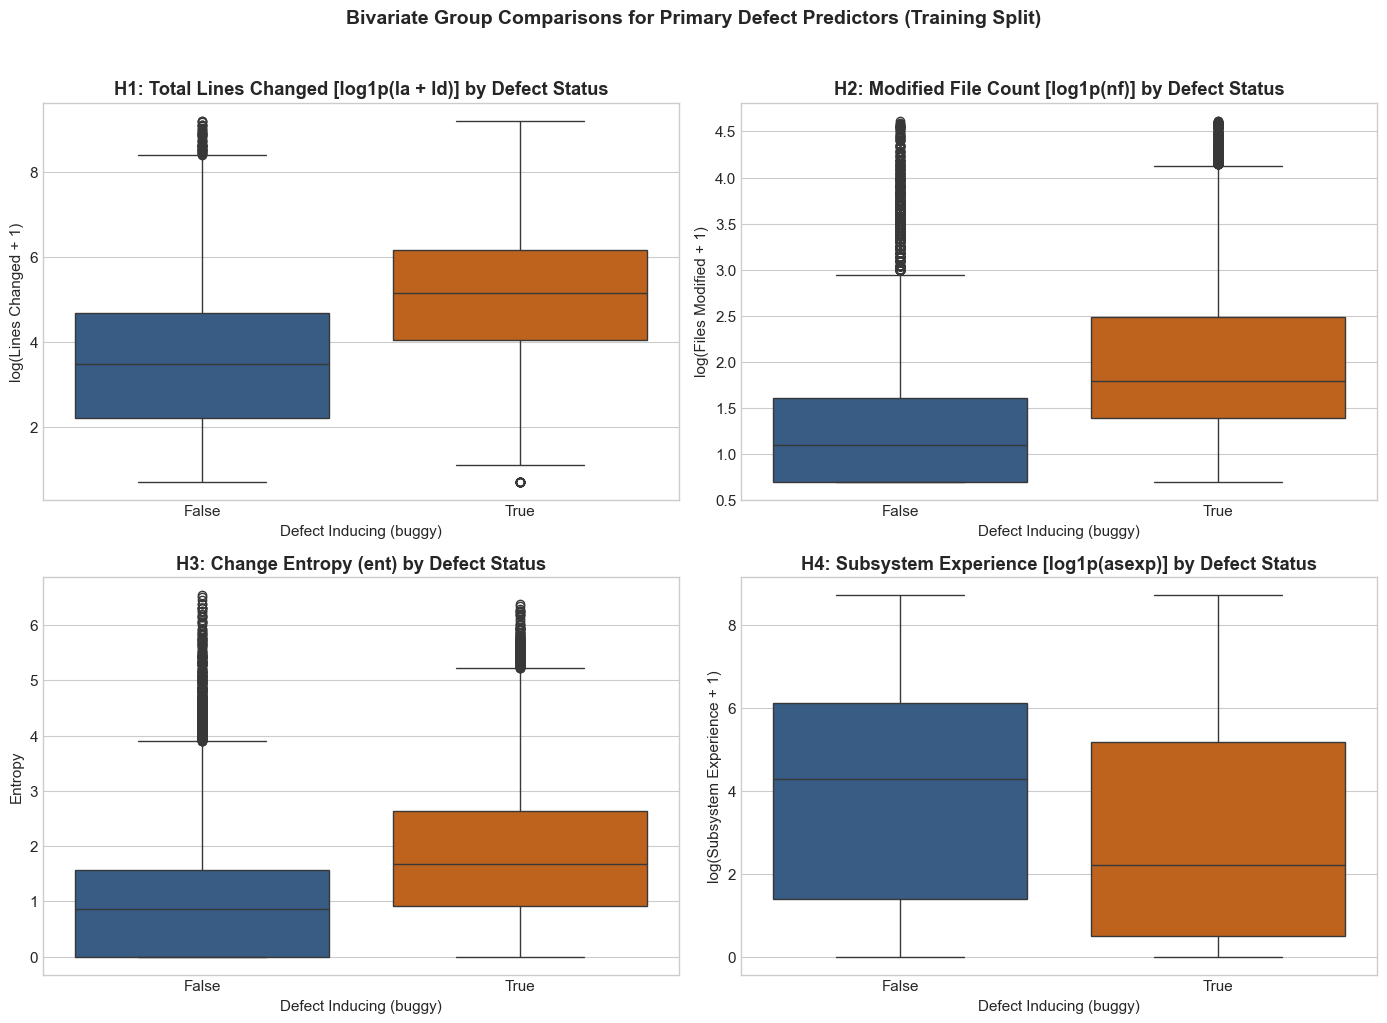

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Total lines changed (log scale)
sns.boxplot(x=df_train['buggy'], y=np.log1p(df_train['la'] + df_train['ld']), ax=axes[0, 0], palette=['#2b5c8f', '#d95f02'])
axes[0, 0].set_title('H1: Total Lines Changed [log1p(la + ld)] by Defect Status', fontweight='bold')
axes[0, 0].set_xlabel('Defect Inducing (buggy)')
axes[0, 0].set_ylabel('log(Lines Changed + 1)')

# 2. Number of files modified
sns.boxplot(x=df_train['buggy'], y=np.log1p(df_train['nf']), ax=axes[0, 1], palette=['#2b5c8f', '#d95f02'])
axes[0, 1].set_title('H2: Modified File Count [log1p(nf)] by Defect Status', fontweight='bold')
axes[0, 1].set_xlabel('Defect Inducing (buggy)')
axes[0, 1].set_ylabel('log(Files Modified + 1)')

# 3. Change Entropy
sns.boxplot(x=df_train['buggy'], y=df_train['ent'], ax=axes[1, 0], palette=['#2b5c8f', '#d95f02'])
axes[1, 0].set_title('H3: Change Entropy (ent) by Defect Status', fontweight='bold')
axes[1, 0].set_xlabel('Defect Inducing (buggy)')
axes[1, 0].set_ylabel('Entropy')

# 4. Author Subsystem Experience
sns.boxplot(x=df_train['buggy'], y=np.log1p(df_train['asexp']), ax=axes[1, 1], palette=['#2b5c8f', '#d95f02'])
axes[1, 1].set_title('H4: Subsystem Experience [log1p(asexp)] by Defect Status', fontweight='bold')
axes[1, 1].set_xlabel('Defect Inducing (buggy)')
axes[1, 1].set_ylabel('log(Subsystem Experience + 1)')

plt.suptitle('Bivariate Group Comparisons for Primary Defect Predictors (Training Split)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


Hypothesis 5: Chi-Square Test of Independence for Project Defect Rates
Chi2 = 8478.95, df = 14, p-value = 0.00e+00
Cramer's V = 0.4349 (Medium association)


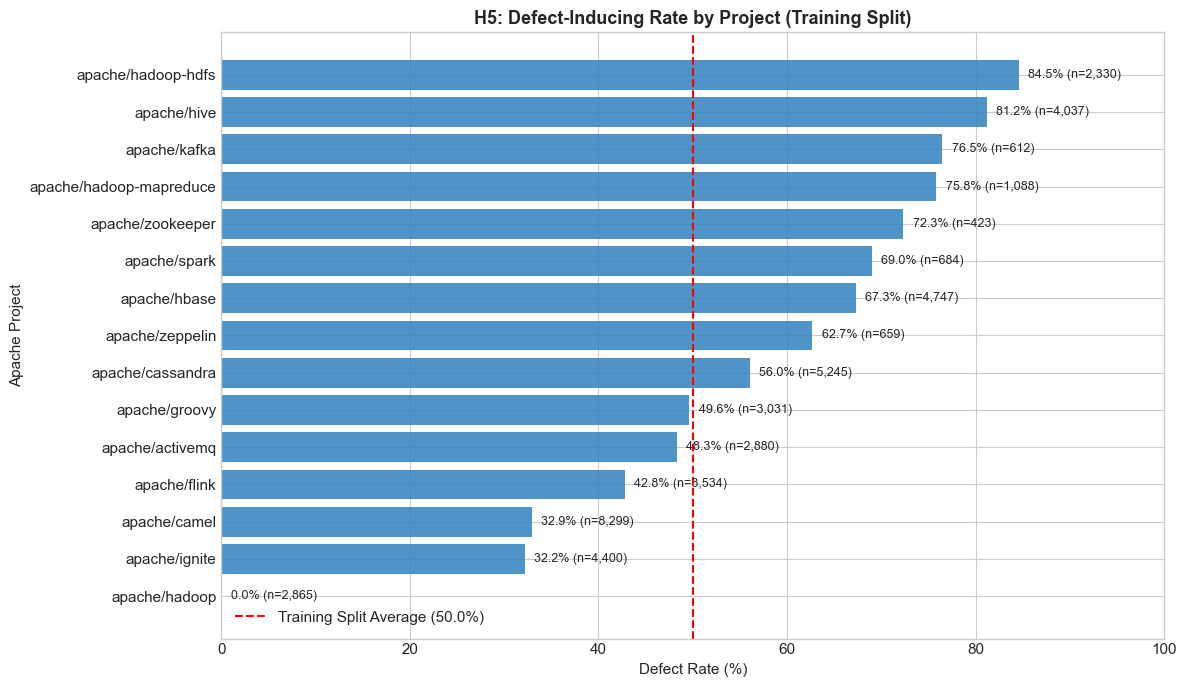

In [7]:
h5 = hypothesis_results['categorical_hypothesis_h5']
print(f"Hypothesis 5: Chi-Square Test of Independence for Project Defect Rates")
print(f"Chi2 = {h5['test_statistic']}, df = {h5['degrees_of_freedom']}, p-value = {h5['raw_p_value']:.2e}")
print(f"Cramer's V = {h5['effect_size_value']} ({h5['effect_size_magnitude']} association)")

proj_df = pd.DataFrame(h5['project_rates']).T.sort_values('defect_rate_pct', ascending=True)

plt.figure(figsize=(12, 7))
bars = plt.barh(proj_df.index, proj_df['defect_rate_pct'], color='#3182bd', alpha=0.85)
plt.axvline(x=50.0, color='red', linestyle='--', label='Training Split Average (50.0%)')
plt.title('H5: Defect-Inducing Rate by Project (Training Split)', fontsize=13, fontweight='bold')
plt.xlabel('Defect Rate (%)')
plt.ylabel('Apache Project')
plt.legend()

# Annotate sample sizes
for bar, (proj, row) in zip(bars, proj_df.iterrows()):
    plt.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2.0, f"{row['defect_rate_pct']:.1f}% (n={int(row['total_commits']):,})", va='center', fontsize=9)

plt.xlim(0, 100)
plt.tight_layout()
plt.show()


In [8]:
print("Variance Inflation Factor (VIF) Diagnostics on Original Numeric Features:")
vif_table = compute_vif(df_train, ORIGINAL_NUMERIC_FEATURES)
display(vif_table)


Variance Inflation Factor (VIF) Diagnostics on Original Numeric Features:


,feature,vif,multicollinearity_risk
9,aexp,13.71,High (VIF > 10)
10,arexp,12.82,High (VIF > 10)
2,nf,4.97,Low (VIF < 5)
3,nd,3.47,Low (VIF < 5)
5,ent,3.06,Low (VIF < 5)
11,asexp,2.83,Low (VIF < 5)
6,ndev,2.75,Low (VIF < 5)
8,nuc,2.64,Low (VIF < 5)
4,ns,1.50,Low (VIF < 5)
0,la,1.38,Low (VIF < 5)


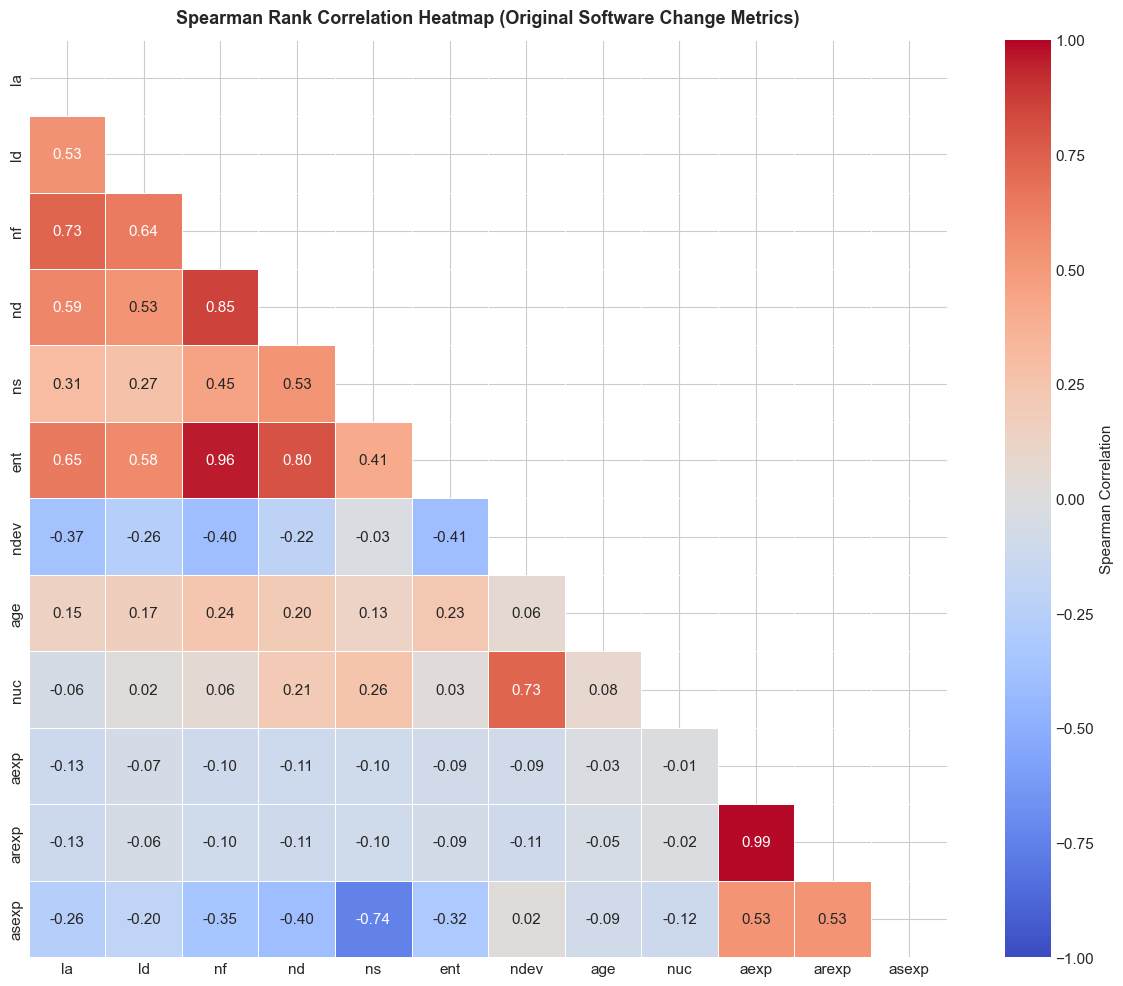

In [9]:
plt.figure(figsize=(12, 10))
corr = df_train[ORIGINAL_NUMERIC_FEATURES].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Spearman Correlation'}
)
plt.title('Spearman Rank Correlation Heatmap (Original Software Change Metrics)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


In [10]:
processed_dir = Path('../data/processed')
if not processed_dir.exists():
    processed_dir = Path('data/processed')

f_train_feat = processed_dir / 'phase2_train_features.csv'
f_test_feat = processed_dir / 'phase2_test_features.csv'
f_train_lbl = processed_dir / 'phase2_train_labels.csv'
f_test_lbl = processed_dir / 'phase2_test_labels.csv'
f_schema = processed_dir / 'feature_schema.json'

print("Verifying processed dataset outputs on disk:")
for p in [f_train_feat, f_test_feat, f_train_lbl, f_test_lbl, f_schema]:
    size_mb = p.stat().st_size / (1024**2)
    print(f"  * {p.name:30s}: {p.stat().st_size:,} bytes ({size_mb:.2f} MB)")


Verifying processed dataset outputs on disk:
  * phase2_train_features.csv     : 12,334,975 bytes (11.76 MB)
  * phase2_test_features.csv      : 8,289,293 bytes (7.91 MB)
  * phase2_train_labels.csv       : 2,129,628 bytes (2.03 MB)
  * phase2_test_labels.csv        : 1,439,527 bytes (1.37 MB)
  * feature_schema.json           : 4,496 bytes (0.00 MB)


### Phase 2 Key Statistical Takeaways & Phase 3 Modeling Recommendations

1. **Size Churn Dominance (H1):** Code change size (`total_lines_changed`) has the highest bivariate effect size (Cliff's $\delta = 0.5043$, Large). Defect-inducing commits modify over 5.5x more lines in median than clean commits.
2. **Diffusion Dispersion (H2 & H3):** High file counts (`nf`, $\delta = 0.4452$) and entropy (`ent`, $\delta = 0.3946$) significantly correlate with higher defect risk.
3. **Experience Protective Factor (H4):** Subsystem experience (`asexp`, $\delta = -0.2548$) is strongly protective. Developers working outside familiar modules exhibit markedly higher defect risk.
4. **Multicollinearity Caution:** Severe collinearity exists between `aexp` and `arexp` (VIF > 12). Tree-based ensembles (Random Forest, LightGBM, XGBoost) are inherently robust to this, while linear models require regularization or feature reduction.
5. **Leakage Safeguards Preserved:** Feature matrices contain strictly 26 approved predictor features with zero test lookahead bias or label contamination.
